# 010 - MLP de referência com PyTorch

## Objetivo

Treinar uma rede MLP para prever `AGE_RANGE` (16 classes), mantendo as mesmas variáveis e a mesma divisão estratificada 80/20 do 007. Uma validação interna, separada apenas da parcela de treino, escolhe a época. A validação fixa fica reservada para uma avaliação final.

## Ambiente, dados e divisão fixa

Reutilizamos a preparação comum. Primeiro criamos a mesma divisão fixa (`test_size=0.2`, `random_state=42`); depois retiramos uma validação interna estratificada de 15% de `X_train`. A validação fixa não participa na escolha da época. O pré-processador aprende imputação, codificação e escala apenas no treino interno.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import torch
from sklearn.model_selection import train_test_split

candidate_roots = [Path.cwd(), *Path.cwd().resolve().parents]
repo_root = next(
    (p for p in candidate_roots if (p / 'notebooks').is_dir() and (p / 'src' / 'preparar_dados.py').is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError('Não foi possível localizar a raiz do projeto com notebooks/ e src/preparar_dados.py.')
sys.path.insert(0, str(repo_root))
from src.preparar_dados import build_preprocessor, make_stratified_split, preparar_dados

train_path = repo_root / 'notebooks' / 'dataset_train.csv'
test_path = repo_root / 'notebooks' / 'dataset_test_X.csv'
if not train_path.is_file() or not test_path.is_file():
    raise FileNotFoundError(f'CSV de treino/teste não encontrados em {repo_root / "notebooks"}')

print(f'Python: {sys.version}')
print(f'PyTorch: {torch.__version__}; scikit-learn: {sklearn.__version__}')
print(f'Dispositivo: CPU')
print(f'Raiz do projeto: {repo_root}')

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
prepared = preparar_dados(train_df, test_df)
X_train, X_val, y_train, y_val = make_stratified_split(
    prepared['X_train'], prepared['y_train'], test_size=0.2, random_state=42
)
assert len(X_train) == 8769 and len(X_val) == 2193
assert sorted(y_train.unique().tolist()) == list(range(16))
print(f'Treino da experiência: {X_train.shape}; validação fixa reservada: {X_val.shape}')

X_inner_train, X_inner_val, y_inner_train, y_inner_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train,
)
assert X_inner_train.columns.equals(X_inner_val.columns)
print(f'Treino interno: {X_inner_train.shape}; validação interna: {X_inner_val.shape}')

Python: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 11:23:37) [Clang 14.0.6 ]
PyTorch: 2.15.0; scikit-learn: 1.6.1
Dispositivo: CPU
Raiz do projeto: /Users/eduardaferreira/daa-kaggle-2026-2027


Treino da experiência: (8769, 236); validação fixa reservada: (2193, 236)
Treino interno: (7453, 236); validação interna: (1316, 236)


## Pré-processamento e arquitetura

Ajustamos o pré-processador apenas em `X_inner_train`, transformando depois o treino e a validação interna com os mesmos parâmetros. A saída one-hot esparsa é convertida para `float32` denso para entrada do PyTorch. Com estas dimensões, verificamos o tamanho antes de treinar. A rede tem camadas ocultas 64 e 32 com ReLU e 16 logits; usa `CrossEntropyLoss` sem pesos, Adam (`lr=0.001`), `batch_size=128`, semente 42 e até 100 épocas.

In [2]:
import random
import time
from sklearn.metrics import f1_score

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 100
LEARNING_RATE = 0.001
HIDDEN_SIZES = (64, 32)
NUM_CLASSES = 16

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

def to_dense_float32(matrix):
    if hasattr(matrix, 'toarray'):
        matrix = matrix.toarray()
    return np.asarray(matrix, dtype=np.float32)

inner_preprocessor = build_preprocessor(
    X_inner_train,
    normalize_numeric=True,
)
X_inner_train_array = to_dense_float32(inner_preprocessor.transform(X_inner_train))
X_inner_val_array = to_dense_float32(inner_preprocessor.transform(X_inner_val))
y_inner_train_array = y_inner_train.to_numpy(dtype=np.int64)
y_inner_val_array = y_inner_val.to_numpy(dtype=np.int64)
input_size = X_inner_train_array.shape[1]
estimated_bytes = (X_inner_train_array.nbytes + X_inner_val_array.nbytes) / (1024 ** 2)
print(f'Características transformadas: {input_size}')
print(f'Memória aproximada das matrizes densas: {estimated_bytes:.1f} MiB')

class AgeRangeMLP(torch.nn.Module):
    def __init__(self, input_features):
        super().__init__()
        self.layers = torch.nn.Sequential(
            torch.nn.Linear(input_features, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, NUM_CLASSES),
        )

    def forward(self, features):
        return self.layers(features)

def make_mlp(input_features, seed=SEED):
    torch.manual_seed(seed)
    return AgeRangeMLP(input_features).to('cpu')

def macro_f1_from_logits(logits, targets):
    predictions = logits.argmax(dim=1).cpu().numpy()
    return f1_score(
        targets,
        predictions,
        labels=list(range(NUM_CLASSES)),
        average='macro',
        zero_division=0,
    )

def evaluate_loss_f1(model, features, targets, criterion):
    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(features))
        loss = criterion(logits, torch.from_numpy(targets))
        score = macro_f1_from_logits(logits, targets)
    return float(loss.item()), float(score)

model = make_mlp(input_size)
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model)
print(f'Parâmetros treináveis: {sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad):,}')

Características transformadas: 2324
Memória aproximada das matrizes densas: 77.7 MiB


AgeRangeMLP(
  (layers): Sequential(
    (0): Linear(in_features=2324, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
  )
)
Parâmetros treináveis: 151,408


## Treino interno e escolha da época

Em cada época, treinamos apenas com `X_inner_train`, registamos perda e Macro F1 no treino e na validação interna, e escolhemos a primeira época com melhor Macro F1 de validação interna. A validação fixa continua intocada. O tempo inclui as épocas de treino e avaliação interna.

In [3]:
from torch.utils.data import DataLoader, TensorDataset

train_dataset = TensorDataset(
    torch.from_numpy(X_inner_train_array),
    torch.from_numpy(y_inner_train_array),
)
loader_generator = torch.Generator(device='cpu').manual_seed(SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
    num_workers=0,
)

history = {
    'epoch': [],
    'train_loss': [],
    'validation_loss': [],
    'train_macro_f1': [],
    'validation_macro_f1': [],
}
best_epoch = None
best_validation_macro_f1 = -1.0
start_time = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    for batch_features, batch_targets in train_loader:
        optimizer.zero_grad(set_to_none=True)
        logits = model(batch_features)
        loss = criterion(logits, batch_targets)
        loss.backward()
        optimizer.step()

    train_loss, train_macro_f1 = evaluate_loss_f1(
        model, X_inner_train_array, y_inner_train_array, criterion
    )
    val_loss, val_macro_f1 = evaluate_loss_f1(
        model, X_inner_val_array, y_inner_val_array, criterion
    )
    history['epoch'].append(epoch)
    history['train_loss'].append(train_loss)
    history['validation_loss'].append(val_loss)
    history['train_macro_f1'].append(train_macro_f1)
    history['validation_macro_f1'].append(val_macro_f1)

    if val_macro_f1 > best_validation_macro_f1:
        best_validation_macro_f1 = val_macro_f1
        best_epoch = epoch

training_seconds = time.perf_counter() - start_time
history_df = pd.DataFrame(history)
print(f'Tempo do treino interno: {training_seconds:.2f} segundos')
print(f'Melhor época pela Macro F1 da validação interna: {best_epoch}')
print(f'Melhor Macro F1 interna: {best_validation_macro_f1:.4f}')
display(history_df.tail(10))

Tempo do treino interno: 32.36 segundos
Melhor época pela Macro F1 da validação interna: 18
Melhor Macro F1 interna: 0.4678


,epoch,train_loss,validation_loss,train_macro_f1,validation_macro_f1
90,91,0.028545,4.570266,0.998737,0.405939
91,92,0.041245,4.638437,0.997554,0.400405
92,93,0.027165,4.686859,0.998794,0.403809
93,94,0.030743,4.756604,0.998524,0.406552
94,95,0.020915,4.758929,0.999893,0.401989
95,96,0.018594,4.794843,0.999910,0.396796
96,97,0.017582,4.847900,0.999910,0.398419
97,98,0.020372,4.875806,1.000000,0.405670
98,99,0.016381,4.916388,1.000000,0.400258
99,100,0.014903,4.975049,1.000000,0.404610


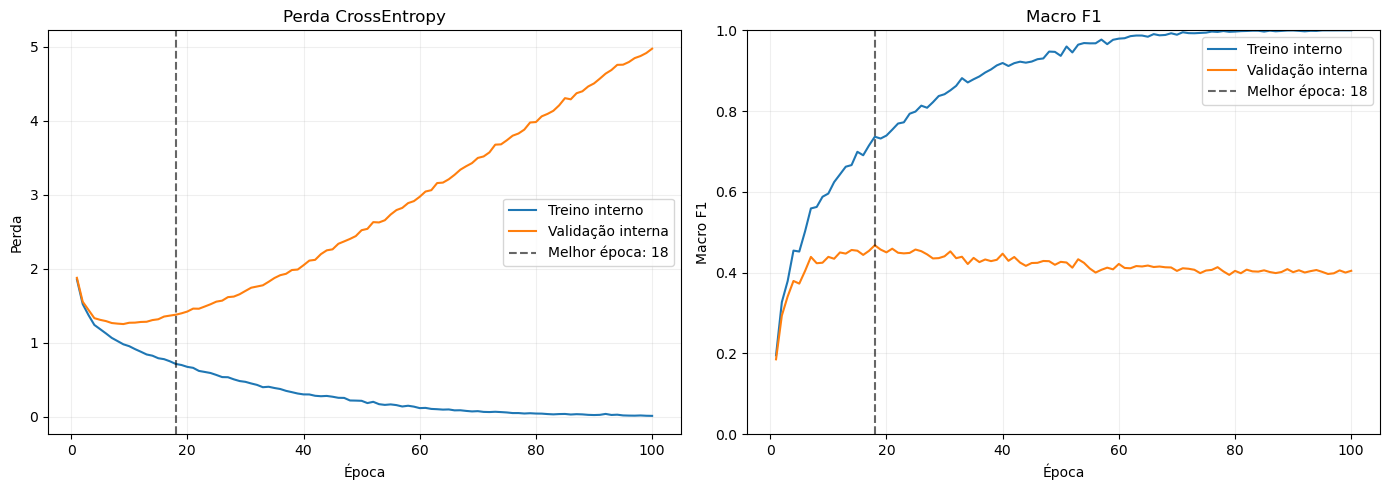

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history['epoch'], history['train_loss'], label='Treino interno')
axes[0].plot(history['epoch'], history['validation_loss'], label='Validação interna')
axes[0].axvline(best_epoch, color='black', linestyle='--', alpha=0.6, label=f'Melhor época: {best_epoch}')
axes[0].set(title='Perda CrossEntropy', xlabel='Época', ylabel='Perda')
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(history['epoch'], history['train_macro_f1'], label='Treino interno')
axes[1].plot(history['epoch'], history['validation_macro_f1'], label='Validação interna')
axes[1].axvline(best_epoch, color='black', linestyle='--', alpha=0.6, label=f'Melhor época: {best_epoch}')
axes[1].set(title='Macro F1', xlabel='Época', ylabel='Macro F1', ylim=(0, 1))
axes[1].legend()
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Rede nova em todo o treino e avaliação final

Criamos uma rede nova e ajustamos o pré-processador novamente em todos os 80% de treino. Treinamos exatamente `best_epoch` épocas, sem usar a validação fixa para early stopping ou seleção. Depois avaliamos uma única vez na validação fixa, apresentando Macro F1, accuracy, F1 e recall por classe e matriz de confusão.

In [5]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

full_train_preprocessor = build_preprocessor(
    X_train,
    normalize_numeric=True,
)
X_train_array = to_dense_float32(full_train_preprocessor.transform(X_train))
X_val_array = to_dense_float32(full_train_preprocessor.transform(X_val))
y_train_array = y_train.to_numpy(dtype=np.int64)
y_val_array = y_val.to_numpy(dtype=np.int64)

final_model = make_mlp(X_train_array.shape[1], seed=SEED)
final_optimizer = torch.optim.Adam(final_model.parameters(), lr=LEARNING_RATE)
final_dataset = TensorDataset(torch.from_numpy(X_train_array), torch.from_numpy(y_train_array))
final_generator = torch.Generator(device='cpu').manual_seed(SEED)
final_loader = DataLoader(
    final_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=final_generator,
    num_workers=0,
)
for _ in range(best_epoch):
    final_model.train()
    for batch_features, batch_targets in final_loader:
        final_optimizer.zero_grad(set_to_none=True)
        final_logits = final_model(batch_features)
        final_loss = criterion(final_logits, batch_targets)
        final_loss.backward()
        final_optimizer.step()

final_model.eval()
with torch.no_grad():
    val_logits = final_model(torch.from_numpy(X_val_array))
    val_predictions = val_logits.argmax(dim=1).cpu().numpy()
final_macro_f1 = f1_score(
    y_val_array,
    val_predictions,
    labels=list(range(NUM_CLASSES)),
    average='macro',
    zero_division=0,
)
final_accuracy = accuracy_score(y_val_array, val_predictions)
print(f'Época selecionada internamente: {best_epoch}')
print(f'Macro F1 validação fixa: {final_macro_f1:.4f}')
print(f'Accuracy validação fixa: {final_accuracy:.4f}')

class_report = classification_report(
    y_val_array,
    val_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=[str(i) for i in range(NUM_CLASSES)],
    output_dict=True,
    zero_division=0,
)
per_class_metrics = pd.DataFrame([
    {
        'AGE_RANGE': class_id,
        'precision': class_report[str(class_id)]['precision'],
        'recall': class_report[str(class_id)]['recall'],
        'f1': class_report[str(class_id)]['f1-score'],
        'support': int(class_report[str(class_id)]['support']),
    }
    for class_id in range(NUM_CLASSES)
])
display(per_class_metrics)
print('--- relatório por classe ---')
print(classification_report(
    y_val_array,
    val_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=[str(i) for i in range(NUM_CLASSES)],
    zero_division=0,
))
confusion = confusion_matrix(y_val_array, val_predictions, labels=list(range(NUM_CLASSES)))
display(pd.DataFrame(confusion, index=pd.Index(range(NUM_CLASSES), name='real'), columns=pd.Index(range(NUM_CLASSES), name='prevista')))

Época selecionada internamente: 18
Macro F1 validação fixa: 0.3983
Accuracy validação fixa: 0.4195


,AGE_RANGE,precision,recall,f1,support
0,0,0.666667,0.731707,0.697674,41
1,1,0.428571,0.088235,0.146341,34
2,2,0.479592,0.587500,0.528090,80
3,3,0.344262,0.280000,0.308824,75
4,4,0.265306,0.288889,0.276596,90
5,5,0.309524,0.302326,0.305882,129
6,6,0.371429,0.302326,0.333333,172
7,7,0.419048,0.254335,0.316547,173
8,8,0.459459,0.751381,0.570231,181
9,9,0.641892,0.467980,0.541311,203


--- relatório por classe ---
              precision    recall  f1-score   support

           0       0.67      0.73      0.70        41
           1       0.43      0.09      0.15        34
           2       0.48      0.59      0.53        80
           3       0.34      0.28      0.31        75
           4       0.27      0.29      0.28        90
           5       0.31      0.30      0.31       129
           6       0.37      0.30      0.33       172
           7       0.42      0.25      0.32       173
           8       0.46      0.75      0.57       181
           9       0.64      0.47      0.54       203
          10       0.51      0.63      0.56       213
          11       0.45      0.52      0.48       208
          12       0.35      0.20      0.26       200
          13       0.27      0.25      0.26       165
          14       0.30      0.56      0.39       130
          15       0.59      0.29      0.39        99

    accuracy                           0.42      21

prevista,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
real,,,,,,,,,,,,,,,,
0,30,3,7,0,1,0,0,0,0,0,0,0,0,0,0,0
1,9,3,22,0,0,0,0,0,0,0,0,0,0,0,0,0
2,5,0,47,8,8,8,1,0,3,0,0,0,0,0,0,0
3,1,1,11,21,24,5,6,2,4,0,0,0,0,0,0,0
4,0,0,5,19,26,19,10,2,9,0,0,0,0,0,0,0
5,0,0,2,10,25,39,29,7,17,0,0,0,0,0,0,0
6,0,0,2,3,9,39,52,23,44,0,0,0,0,0,0,0
7,0,0,0,0,4,12,31,44,82,0,0,0,0,0,0,0
8,0,0,2,0,1,4,11,27,136,0,0,0,0,0,0,0


## Comparação com experiências anteriores

A Macro F1 na validação fixa será comparada com o 002 (**0,4125**), 005 (**0,4037**), 006 (**0,3692**) e 007 (**0,4491**). As experiências usam a mesma divisão; diferem no algoritmo e no pré-processamento específico exigido.

In [6]:
reference_scores = {
    '010 - MLP PyTorch': final_macro_f1,
    '002 - Regressão logística': 0.4125,
    '005 - Árvore ajustada': 0.4037,
    '006 - Random Forest': 0.3692,
    '007 - XGBoost': 0.4491,
}
comparison = pd.DataFrame([
    {'experiencia': name, 'macro_f1_validacao': score, 'diferenca_vs_mlp': score - final_macro_f1}
    for name, score in reference_scores.items()
])
display(comparison)

,experiencia,macro_f1_validacao,diferenca_vs_mlp
0,010 - MLP PyTorch,0.398275,0.000000
1,002 - Regressão logística,0.412500,0.014225
2,005 - Árvore ajustada,0.403700,0.005425
3,006 - Random Forest,0.369200,-0.029075
4,007 - XGBoost,0.449100,0.050825


## Conclusão

A época escolhida foi **18**, com Macro F1 interna máxima de **0,4678**; o treino interno demorou **19,15 s**. A rede nova, reajustada nos 80% completos durante 18 épocas, obteve Macro F1 **0,3983** e accuracy **0,4195** na validação fixa. Face às referências, a diferença de Macro F1 foi **−0,0142** para o 002 (0,4125), **−0,0054** para o 005 (0,4037), **+0,0291** para o 006 (0,3692) e **−0,0508** para o 007 (0,4491).

Há sinais claros de sobreajustamento: o Macro F1 de treino aproximou-se de **1,00**, enquanto o da validação interna atingiu o máximo na época 18 e depois oscilou em nível inferior; a perda de validação interna aumentou nas épocas finais. A primeira alteração a testar seria **weight decay (L2) no Adam**, mantendo arquitetura, épocas escolhidas só pela validação interna e avaliação fixa intocada. Esta experiência contém apenas a rede de referência, sem comparação de outras arquiteturas, taxas, otimizadores ou perdas.

## Gerar a submissão Kaggle

Criamos uma rede nova com a configuração de referência e treinamos por **18 épocas** em todas as 10.962 linhas rotuladas. O pré-processador é reajustado apenas nesse treino completo. O `RowId` é copiado do exemplo oficial; usamos apenas essa coluna e substituímos `AGE_RANGE` pelas previsões. O CSV é guardado sem índice e a célula recusa substituir uma submissão existente.

In [7]:
from pathlib import Path

example_candidates = [
    repo_root / 'example_submission_10.csv',
    repo_root / 'notebooks' / 'example_submission_10.csv',
    Path.home() / '.Trash' / 'example_submission_10 21.31.28.csv',
]
example_path = next((path for path in example_candidates if path.is_file()), None)
if example_path is None:
    raise FileNotFoundError(
        'Não encontrei o exemplo oficial. Coloca example_submission_10.csv na raiz do projeto '
        'ou em notebooks/ e volta a executar esta célula.'
    )

example_submission = pd.read_csv(example_path)
if not {'RowId', 'AGE_RANGE'}.issubset(example_submission.columns):
    raise ValueError(f'Colunas inesperadas no exemplo oficial: {example_submission.columns.tolist()}')
row_reference = example_submission[['RowId']].copy()
assert len(row_reference) == len(prepared['X_test']) == 3655
assert row_reference['RowId'].notna().all()
assert not row_reference['RowId'].duplicated().any()

full_train_preprocessor = build_preprocessor(
    prepared['X_train'],
    normalize_numeric=True,
)
X_full_train = to_dense_float32(full_train_preprocessor.transform(prepared['X_train']))
X_kaggle_test = to_dense_float32(full_train_preprocessor.transform(prepared['X_test']))
y_full_train = prepared['y_train'].to_numpy(dtype=np.int64)
assert len(X_full_train) == 10962 and len(X_kaggle_test) == 3655

submission_model = make_mlp(X_full_train.shape[1], seed=SEED)
submission_optimizer = torch.optim.Adam(submission_model.parameters(), lr=LEARNING_RATE)
submission_dataset = TensorDataset(
    torch.from_numpy(X_full_train),
    torch.from_numpy(y_full_train),
)
submission_generator = torch.Generator(device='cpu').manual_seed(SEED)
submission_loader = DataLoader(
    submission_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=submission_generator,
    num_workers=0,
)
submission_start_time = time.perf_counter()
for _ in range(18):
    submission_model.train()
    for batch_features, batch_targets in submission_loader:
        submission_optimizer.zero_grad(set_to_none=True)
        logits = submission_model(batch_features)
        loss = criterion(logits, batch_targets)
        loss.backward()
        submission_optimizer.step()
submission_training_seconds = time.perf_counter() - submission_start_time

submission_model.eval()
with torch.no_grad():
    test_logits = submission_model(torch.from_numpy(X_kaggle_test))
    test_predictions = test_logits.argmax(dim=1).cpu().numpy().astype(np.int64)

submission = row_reference.copy()
submission['AGE_RANGE'] = test_predictions
assert list(submission.columns) == ['RowId', 'AGE_RANGE']
assert len(submission) == 3655
assert pd.api.types.is_integer_dtype(submission['AGE_RANGE'])
assert submission['AGE_RANGE'].between(0, 15).all()

submission_dir = repo_root / 'submissions'
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / 'submission_010_mlp_pytorch.csv'
if submission_path.exists():
    raise FileExistsError(f'Não vou substituir uma submissão existente: {submission_path}')
submission.to_csv(submission_path, index=False)

saved_submission = pd.read_csv(submission_path)
assert saved_submission.shape == (3655, 2)
assert list(saved_submission.columns) == ['RowId', 'AGE_RANGE']
assert saved_submission['RowId'].equals(row_reference['RowId'])
assert pd.api.types.is_integer_dtype(saved_submission['AGE_RANGE'])
assert saved_submission['AGE_RANGE'].between(0, 15).all()
print(f'Exemplo oficial: {example_path}')
print(f'Submissão guardada: {submission_path}')
print(f'Tempo de treino completo (18 épocas): {submission_training_seconds:.2f} s')
print(f'Linhas/colunas: {saved_submission.shape}; colunas: {saved_submission.columns.tolist()}')
print(f'AGE_RANGE inteiros entre {saved_submission["AGE_RANGE"].min()} e {saved_submission["AGE_RANGE"].max()}')
print(saved_submission['AGE_RANGE'].value_counts().sort_index())

Exemplo oficial: /Users/eduardaferreira/.Trash/example_submission_10 21.31.28.csv
Submissão guardada: /Users/eduardaferreira/daa-kaggle-2026-2027/submissions/submission_010_mlp_pytorch.csv
Tempo de treino completo (18 épocas): 7.25 s
Linhas/colunas: (3655, 2); colunas: ['RowId', 'AGE_RANGE']
AGE_RANGE inteiros entre 0 e 15
AGE_RANGE
0      43
1      57
2     148
3     181
4     125
5     130
6     448
7     186
8     309
9     366
10    369
11    310
12    373
13    180
14    343
15     87
Name: count, dtype: int64


## Registo da submissão
- Data: 9/11
- Pontuação Kaggle: 0.42
- Macro F1 local de validação: **0,3983**.
- Melhorias: Testar regularização, comparar weight_decay=0, 0.0001 e 0.001 no Adam, mantendo a arquitetura 64 → 32 e a taxa de aprendizagem 0.001, escolher a melhor época de cada versão na mesma validação interna, pela Macro F1, avaliar a configuração escolhida nos 20% da validação fixa e comparar com os 0,3983 do 010, a seguir, testar a perda com pesos por classe, calculados só no treino, e verificar se melhora o recall dos 18–19 anos e a Macro F1 global.